In [3]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving cars_for_python.csv to cars_for_python.csv
['cars_for_python.csv']


Rows: 193
Pearson  (power vs price):      0.721
Spearman (power vs price):      0.863
Pearson  (power vs log price):  0.798


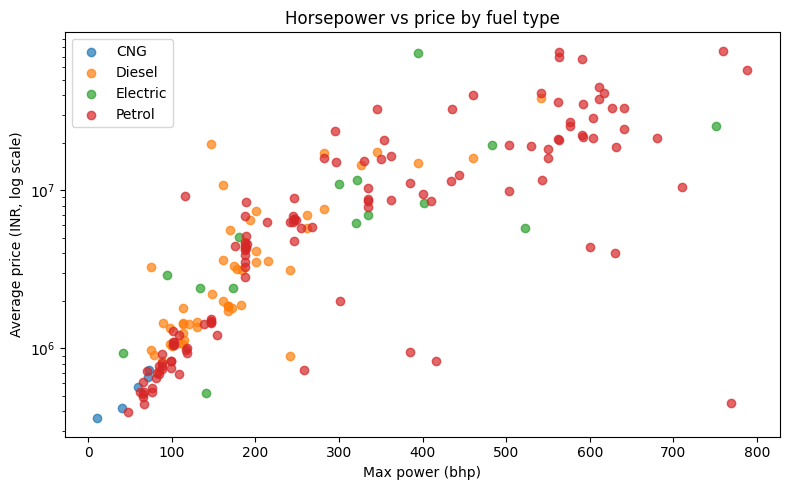

In [4]:
# Question 7:
# How strongly is horsepower related to price?
# Prices are highly skewed, so we also test with log-transformed price.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cols = ["car_id", "brand", "car_name", "fuel_type", "body_type",
        "price_segment", "max_power_bhp", "avg_price"]
df = pd.read_csv("cars_for_python.csv", header=None, names=cols)

df["log_price"] = np.log10(df["avg_price"])

print("Rows:", len(df))
print("Pearson  (power vs price):     ", round(df["max_power_bhp"].corr(df["avg_price"]), 3))
print("Spearman (power vs price):     ", round(df["max_power_bhp"].corr(df["avg_price"], method="spearman"), 3))
print("Pearson  (power vs log price): ", round(df["max_power_bhp"].corr(df["log_price"]), 3))

plt.figure(figsize=(8, 5))
for fuel, g in df.groupby("fuel_type"):
    plt.scatter(g["max_power_bhp"], g["avg_price"], label=fuel, alpha=0.7)
plt.yscale("log")
plt.xlabel("Max power (bhp)")
plt.ylabel("Average price (INR, log scale)")
plt.title("Horsepower vs price by fuel type")
plt.legend()
plt.tight_layout()
plt.savefig("power_vs_price.png", dpi=150)
plt.show()

In [ ]:
# Finding: Horsepower has a strong positive relationship with price.
# Pearson 0.721 | Spearman 0.863 | Pearson on log(price) 0.798 (n = 193).
# The Spearman value is higher than Pearson because the relationship is
# consistently rising but not a straight line: prices climb faster
# than power, especially above ~300 bhp.
# The scatter plot shows the same trend across Petrol, Diesel and Electric
# cars, so fuel type does not change the overall pattern.
# Caveat: correlation is not causation, and the remaining spread shows
# that power alone does not determine price (brand, size and features matter).
# Some petrol cars have high power at relatively low prices (value outliers).